In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split

In [2]:
DATA_PATH = Path("../data/raw/creditcard.csv")

df = pd.read_csv(DATA_PATH)

X = df.drop(columns=["Class"])
y = df["Class"]

print("Dimensões das features:", X.shape)
print("Dimensões do target:", y.shape)

Dimensões das features: (284807, 30)
Dimensões do target: (284807,)


In [3]:
# Primeira divisão: 70% treino e 30% temporário
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Segunda divisão: 15% validação e 15% teste
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Treino:", X_train.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

Treino: (199364, 30)
Validação: (42721, 30)
Teste: (42722, 30)


In [4]:
datasets = {
    "Treino": y_train,
    "Validação": y_val,
    "Teste": y_test
}

for name, target in datasets.items():
    fraud_count = (target == 1).sum()
    fraud_percentage = target.mean() * 100

    print(f"{name}:")
    print(f"  Total: {len(target)}")
    print(f"  Fraudes: {fraud_count}")
    print(f"  Percentual de fraude: {fraud_percentage:.4f}%")
    print()

Treino:
  Total: 199364
  Fraudes: 344
  Percentual de fraude: 0.1725%

Validação:
  Total: 42721
  Fraudes: 74
  Percentual de fraude: 0.1732%

Teste:
  Total: 42722
  Fraudes: 74
  Percentual de fraude: 0.1732%



In [5]:
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

In [6]:
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(X_train, y_train)

print("Baseline treinado com sucesso!")

Baseline treinado com sucesso!


In [7]:
y_pred_dummy = dummy_model.predict(X_val)

print("Primeiras 20 previsões:")
print(y_pred_dummy[:20])

print("\nQuantidade prevista por classe:")
print(pd.Series(y_pred_dummy).value_counts())

Primeiras 20 previsões:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Quantidade prevista por classe:
0    42721
Name: count, dtype: int64


In [8]:
accuracy = accuracy_score(y_val, y_pred_dummy)

precision = precision_score(
    y_val,
    y_pred_dummy,
    zero_division=0
)

recall = recall_score(
    y_val,
    y_pred_dummy,
    zero_division=0
)

f1 = f1_score(
    y_val,
    y_pred_dummy,
    zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nMatriz de confusão:")
print(confusion_matrix(y_val, y_pred_dummy))

Accuracy:  0.9983
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000

Matriz de confusão:
[[42647     0]
 [   74     0]]


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [10]:
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

print(logistic_pipeline)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])


In [11]:
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression treinada com sucesso!")

Logistic Regression treinada com sucesso!


In [12]:
y_pred_logistic = logistic_pipeline.predict(X_val)

y_proba_logistic = logistic_pipeline.predict_proba(X_val)[:, 1]

print("Primeiras 10 previsões:")
print(y_pred_logistic[:10])

print("\nPrimeiros 10 scores de fraude:")
print(y_proba_logistic[:10])

print("\nQuantidade prevista por classe:")
print(pd.Series(y_pred_logistic).value_counts())

Primeiras 10 previsões:
[0 0 0 0 0 0 0 0 0 0]

Primeiros 10 scores de fraude:
[3.24949824e-04 2.83822126e-03 1.79636701e-06 1.01387250e-01
 1.45506351e-03 1.94047891e-01 3.23896113e-02 8.12950213e-02
 2.16071075e-02 2.40614787e-02]

Quantidade prevista por classe:
0    41752
1      969
Name: count, dtype: int64


In [13]:
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    roc_auc_score
)

print("=== LOGISTIC REGRESSION ===")

print(classification_report(
    y_val,
    y_pred_logistic,
    digits=4,
    zero_division=0
))

print(
    "PR-AUC (Average Precision):",
    round(average_precision_score(y_val, y_proba_logistic), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_val, y_proba_logistic), 4)
)

=== LOGISTIC REGRESSION ===
              precision    recall  f1-score   support

           0     0.9998    0.9788    0.9892     42647
           1     0.0671    0.8784    0.1246        74

    accuracy                         0.9786     42721
   macro avg     0.5334    0.9286    0.5569     42721
weighted avg     0.9982    0.9786    0.9877     42721

PR-AUC (Average Precision): 0.6301
ROC-AUC: 0.9684


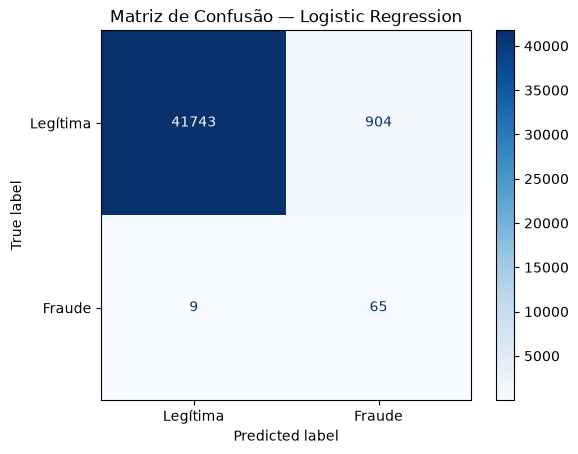

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_logistic,
    display_labels=["Legítima", "Fraude"],
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de Confusão — Logistic Regression")
plt.show()

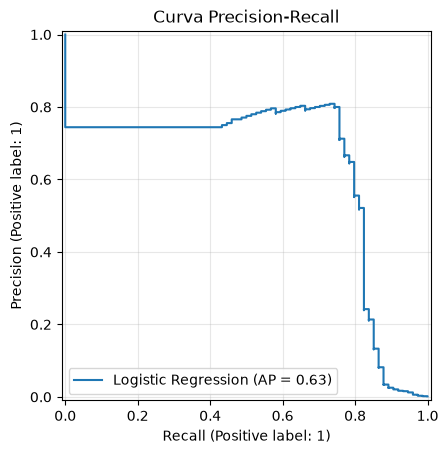

In [18]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_val,
    y_proba_logistic,
    name="Logistic Regression"
)

plt.title("Curva Precision-Recall")
plt.grid(alpha=0.3)
plt.show()

In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

models_results = pd.DataFrame({
    "Modelo": [
        "DummyClassifier",
        "LogisticRegression"
    ],
    "Accuracy": [
        accuracy_score(y_val, y_pred_dummy),
        accuracy_score(y_val, y_pred_logistic)
    ],
    "Precision": [
        precision_score(y_val, y_pred_dummy, zero_division=0),
        precision_score(y_val, y_pred_logistic)
    ],
    "Recall": [
        recall_score(y_val, y_pred_dummy, zero_division=0),
        recall_score(y_val, y_pred_logistic)
    ],
    "F1-score": [
        f1_score(y_val, y_pred_dummy, zero_division=0),
        f1_score(y_val, y_pred_logistic)
    ],
    "Average Precision": [
        average_precision_score(
            y_val,
            dummy_model.predict_proba(X_val)[:, 1]
        ),
        average_precision_score(
            y_val,
            y_proba_logistic
        )
    ]
})

display(models_results.round(4))

,Modelo,Accuracy,Precision,Recall,F1-score,Average Precision
0,DummyClassifier,0.9983,0.0000,0.0000,0.0000,0.0017
1,LogisticRegression,0.9786,0.0671,0.8784,0.1246,0.6301
